# Семинар 3-СС. Есептер жинағы

Бұл дәптерде 3 есеп шешіледі:
1. Үш сүзгінің (орташа, Гаусс, медиана) жауабын қолмен есептеу
2. 1D сигналдағы медиана мен орташа сүзгіні салыстыру
3. Сүзгілеу сапасын бағалау — MSE, PSNR

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)


## Есеп 1: үш сүзгінің жауабын қолмен есептеу

**Берілгені:** орталығында импульстік шуы бар $3\times3$ фрагмент:

$$\begin{bmatrix}10 & 12 & 11 \\ 13 & 255 & 10 \\ 0 & 12 & 11\end{bmatrix}$$

Осы фрагментке **орташа (mean) $3\times3$**, **Гаусс $3\times3$ (салмағы 1/16)** және **медиана $3\times3$** сүзгілерінің орталық пиксельге әсерін есептейміз.

In [2]:
fragment = np.array([
    [10, 12, 11],
    [13, 255, 10],
    [0, 12, 11],
], dtype=np.float64)

# 1) Орташа (mean) сүзгі 3x3
mean_result = fragment.sum() / 9
print(f"Орташа 3x3: сумма={fragment.sum():.0f}, нәтиже = {fragment.sum():.0f}/9 = {mean_result:.1f}")

# 2) Гаусс 3x3 ядросы, салмағы 1/16: [[1,2,1],[2,4,2],[1,2,1]]
gauss_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1],
], dtype=np.float64)
corners = fragment[0, 0] + fragment[0, 2] + fragment[2, 0] + fragment[2, 2]
edges = fragment[0, 1] + fragment[1, 0] + fragment[1, 2] + fragment[2, 1]
center = fragment[1, 1]
gauss_sum = 1 * corners + 2 * edges + 4 * center
gauss_result = gauss_sum / 16
print(f"\nГаусс 3x3 (1/16): бұрыштар=1*{corners:.0f}={1*corners:.0f}, "
      f"қырлар=2*{edges:.0f}={2*edges:.0f}, орталық=4*{center:.0f}={4*center:.0f}")
print(f"қосынды = {gauss_sum:.0f}, нәтиже = {gauss_sum:.0f}/16 = {gauss_result:.2f}")

# 3) Медиана 3x3
sorted_vals = np.sort(fragment.flatten())
median_result = np.median(fragment)
print(f"\nМедиана 3x3: реттелген мәндер = {sorted_vals.astype(int).tolist()}")
print(f"медиана = {median_result:.0f}")

# OpenCV арқылы тексеру
frag_u8 = fragment.astype(np.uint8)
cv_mean = cv2.blur(frag_u8, (3, 3))[1, 1]
cv_gauss = cv2.GaussianBlur(frag_u8, (3, 3), sigmaX=0)[1, 1]
cv_median = cv2.medianBlur(frag_u8, 3)[1, 1]
print(f"\nOpenCV арқылы тексеру (орталық пиксель): mean={cv_mean}, "
      f"gaussian={cv_gauss}, median={cv_median}")


Орташа 3x3: сумма=334, нәтиже = 334/9 = 37.1

Гаусс 3x3 (1/16): бұрыштар=1*32=32, қырлар=2*47=94, орталық=4*255=1020
қосынды = 1146, нәтиже = 1146/16 = 71.62

Медиана 3x3: реттелген мәндер = [0, 10, 10, 11, 11, 12, 12, 13, 255]
медиана = 11

OpenCV арқылы тексеру (орталық пиксель): mean=37, gaussian=72, median=11


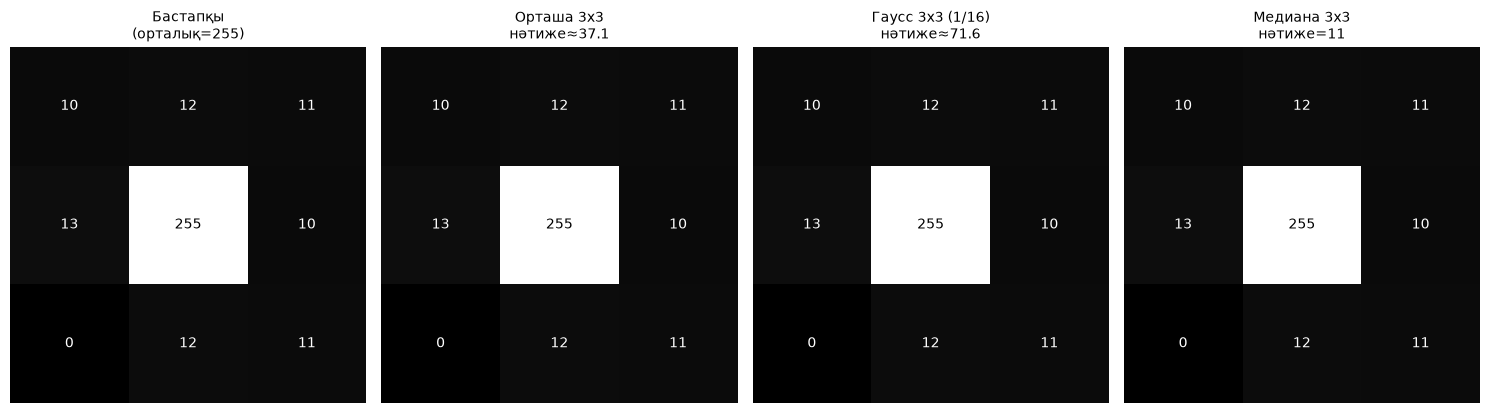


Орталық пиксель мәндері: бастапқы=255, mean=37.1, gaussian=71.6, median=11


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
titles = [
    f"Бастапқы\n(орталық=255)",
    f"Орташа 3x3\nнәтиже≈{mean_result:.1f}",
    f"Гаусс 3x3 (1/16)\nнәтиже≈{gauss_result:.1f}",
    f"Медиана 3x3\nнәтиже={median_result:.0f}",
]
results = [fragment[1, 1], mean_result, gauss_result, median_result]
for ax, title, val in zip(axes, titles, results):
    ax.imshow(fragment, cmap="gray", vmin=0, vmax=255)
    for i in range(3):
        for j in range(3):
            color = "white" if fragment[i, j] < 128 else "black"
            ax.text(j, i, f"{fragment[i, j]:.0f}", ha="center", va="center", color=color)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task1_three_filters.png"), bbox_inches="tight", dpi=120)
plt.show()

print(f"\nОрталық пиксель мәндері: бастапқы=255, mean={mean_result:.1f}, "
      f"gaussian={gauss_result:.1f}, median={median_result:.0f}")


**Қорытынды:** импульстік шуда сызықтық сүзгілер (орташа, Гаусс) қатені толығымен жоя алмайды — олар 255 мәнін көршілерге «жаяды» (mean → 37.1, Gaussian → 71.6, екеуі де әлі де түпнұсқа фонның мәнінен (~10-13) едәуір жоғары). Ал **медиана** сүзгісі шусыз көршілердің арасынан таңдайтындықтан, импульсті (255) толығымен алып тастап, нәтижені шынайы фон деңгейіне (11) қайтарады.

## Есеп 2: 1D сигналдағы медиана мен орташа сүзгі

**Кіріс сигнал:** `[10, 10, 200, 10, 10, 90, 90, 0, 90, 90]` — екі деңгейлі (10 және 90) сатылы сигналға екі импульстік шу (200 және 0) қосылған.

Терезе өлшемі $=3$, шеткі элементтер (бірінші/соңғы) сүзгіленбей, түпнұсқа күйінде қалады (border handling: тек ішкі нүктелер өңделеді).

In [4]:
signal = np.array([10, 10, 200, 10, 10, 90, 90, 0, 90, 90], dtype=np.float64)
n = len(signal)

avg_filtered = signal.copy()
median_filtered = signal.copy()

for i in range(1, n - 1):
    window = signal[i - 1:i + 2]
    avg_filtered[i] = window.mean()
    median_filtered[i] = np.median(window)

print("Кіріс:      ", [f"{v:.0f}" for v in signal])
print("Орташа, 3:  ", [f"{v:.1f}" for v in avg_filtered])
print("Медиана, 3: ", [f"{v:.0f}" for v in median_filtered])

# Слайдтағы мысал: i=2 (0-индекс), терезе [10, 200, 10]
i = 2
window = signal[i - 1:i + 2]
print(f"\nМысал, i={i}: терезе {window.astype(int).tolist()}")
print(f"орташа = {window.sum():.0f}/3 ≈ {window.mean():.1f} · медиана = {np.median(window):.0f}")


Кіріс:       ['10', '10', '200', '10', '10', '90', '90', '0', '90', '90']
Орташа, 3:   ['10.0', '73.3', '73.3', '73.3', '36.7', '63.3', '60.0', '60.0', '60.0', '90.0']
Медиана, 3:  ['10', '10', '10', '10', '10', '90', '90', '90', '90', '90']

Мысал, i=2: терезе [10, 200, 10]
орташа = 220/3 ≈ 73.3 · медиана = 10


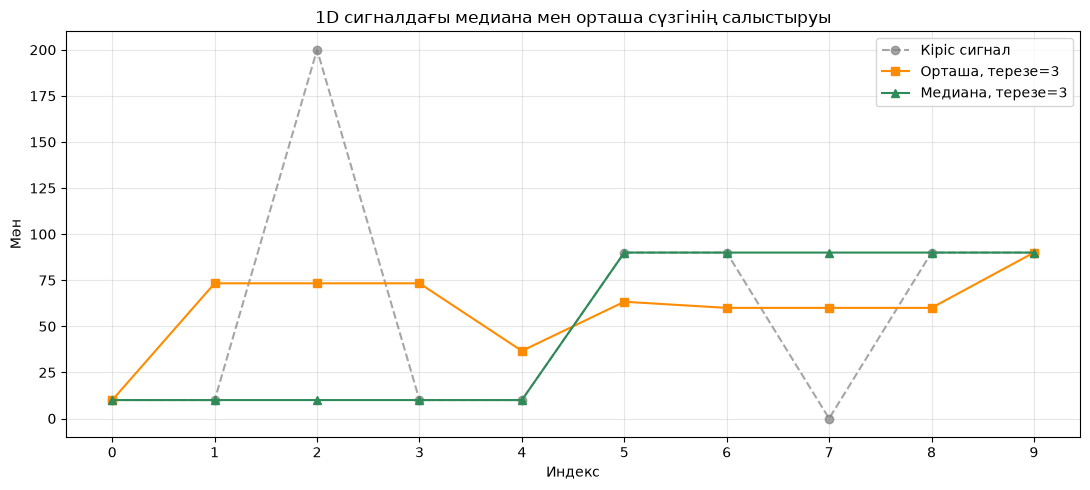

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(n)
ax.plot(x, signal, "o--", color="gray", label="Кіріс сигнал", alpha=0.7)
ax.plot(x, avg_filtered, "s-", color="darkorange", label="Орташа, терезе=3")
ax.plot(x, median_filtered, "^-", color="seagreen", label="Медиана, терезе=3")
ax.set_xticks(x)
ax.set_xlabel("Индекс")
ax.set_ylabel("Мән")
ax.legend()
ax.set_title("1D сигналдағы медиана мен орташа сүзгінің салыстыруы")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task2_1d_signal.png"), bbox_inches="tight", dpi=120)
plt.show()


**Қорытынды:** медиана сүзгісі екі импульсті (200 және 0) толығымен жойып, 10 → 90 сатылы шекараны да өзгеріссіз, өткір күйінде сақтады. Ал орташа сүзгі импульстерді жоя алмай, оларды көршілес нүктелерге «жайды» (мысалы, 73.3 және 36.7 мәндері), әрі сатылы шекараны да бұлдырлатты (60, 63.3 сияқты аралық мәндер пайда болды). Бұл — медиана сүзгісінің шеттерді сақтай отырып импульстік шуды басатынының көрнекі дәлелі.

## Есеп 3: сүзгілеу сапасын бағалау — MSE, PSNR

**Берілгені:** $2\times2$ эталон блок (барлығы 100) және сүзгіден кейінгі нәтиже.

$$MSE = \frac{1}{N}\sum (I - K)^2, \qquad PSNR = 10\lg\left(\frac{MAX^2}{MSE}\right),\ MAX=255$$

In [6]:
reference = np.array([[100, 100], [100, 100]], dtype=np.float64)
filtered = np.array([[102, 98], [101, 99]], dtype=np.float64)

diff_sq = (reference - filtered) ** 2
mse = diff_sq.mean()
psnr = 10 * np.log10(255 ** 2 / mse)

print("Айырмашылық квадраттары:")
print(diff_sq)
print(f"\nMSE = ({'+'.join(str(int(v)) for v in diff_sq.flatten())}) / 4 = "
      f"{diff_sq.sum():.0f} / 4 = {mse:.2f}")
print(f"PSNR = 10*lg(255^2 / {mse:.1f}) = 10*lg({255**2/mse:.1f}) ≈ {psnr:.1f} дБ")

# OpenCV арқылы тексеру
cv_psnr = cv2.PSNR(reference.astype(np.uint8), filtered.astype(np.uint8))
print(f"\nOpenCV cv2.PSNR() арқылы тексеру: {cv_psnr:.2f} дБ")


Айырмашылық квадраттары:
[[4. 4.]
 [1. 1.]]

MSE = (4+4+1+1) / 4 = 10 / 4 = 2.50
PSNR = 10*lg(255^2 / 2.5) = 10*lg(26010.0) ≈ 44.2 дБ

OpenCV cv2.PSNR() арқылы тексеру: 44.15 дБ


**SSIM туралы:** PSNR тек пиксельдік айырмашылықты өлшесе, **SSIM** (Structural Similarity Index) жарықтықты, контрастты және құрылымды бірге салыстырады: $SSIM=1$ — толық ұқсас. SSIM адамның көру қабылдауына PSNR-ға қарағанда жақынырақ, себебі PSNR жоғары болса да, кескін адам көзіне бұрмаланған болып көрінуі мүмкін (немесе керісінше).

### Өз бетінше: $\sigma=20$ Гаусс шуы үшін (сүзгісіз) PSNR неге тең?

Сүзгіленбеген, тек Гаусс шуы қосылған кескін үшін теориялық түрде $MSE \approx \sigma^2$ (шудың дисперсиясы), себебі шу нөлдік ортамен таралған. Мұны нақты кескінге шу қосып, эксперимент арқылы тексереміз.

In [7]:
sigma = 20

# Теориялық болжам: MSE ≈ sigma^2
theoretical_mse = sigma ** 2
theoretical_psnr = 10 * np.log10(255 ** 2 / theoretical_mse)
print(f"Теориялық: MSE ≈ σ² = {theoretical_mse}, "
      f"PSNR = 10*lg(255²/{theoretical_mse}) ≈ {theoretical_psnr:.2f} дБ")

# Эксперимент: нақты фотоға Гаусс шуын қосып тексереміз
img = cv2.imread("images/photo.webp")
np.random.seed(0)
noise = np.random.normal(0, sigma, img.shape)
noisy = np.clip(img.astype(np.float64) + noise, 0, 255).astype(np.uint8)

empirical_mse = np.mean((img.astype(np.float64) - noisy.astype(np.float64)) ** 2)
empirical_psnr = cv2.PSNR(img, noisy)
print(f"\nЭксперимент (нақты фотомен): MSE = {empirical_mse:.2f}, "
      f"PSNR = {empirical_psnr:.2f} дБ")
print("\nТеориялық және эксперименттік мәндер бір-біріне жақын — "
      "бұл MSE ≈ σ² болжамын растайды.")


Теориялық: MSE ≈ σ² = 400, PSNR = 10*lg(255²/400) ≈ 22.11 дБ

Эксперимент (нақты фотомен): MSE = 355.87, PSNR = 22.62 дБ

Теориялық және эксперименттік мәндер бір-біріне жақын — бұл MSE ≈ σ² болжамын растайды.


## Жалпы қорытынды

Осы семинарда импульстік шуды басу мен сапаны бағалаудың негізгі принциптері қарастырылды. Медиана сүзгісі сызықтық сүзгілерден (орташа, Гаусс) айырмашылығы, импульстік шуды (тұз-бұрыш тәрізді бөлек шеткі мәндерді) толығымен жойып, әрі сигналдың өткір шекараларын бұрмаламайды — бұл 1D сигнал мен $3\times3$ фрагмент мысалдарында айқын көрсетілді. PSNR метрикасы сүзгіден кейінгі кескіннің эталонға қаншалықты жақын екенін сандық түрде бағалауға мүмкіндік береді, ал SSIM адам қабылдауына жақынырақ, құрылымдық ұқсастықты өлшейді. Соңында, Гаусс шуының дисперсиясы ($\sigma^2$) мен сүзгісіз кескіннің MSE мәні арасындағы теориялық байланыс эксперимент арқылы расталды.